# Record a custom isolated-word lip-reading dataset

This notebook records mouth-only clips for **Hello, Hi, Yes, No, Good, Bad, Thanks,** and **Bye**. It is designed for repeated use by multiple people: choose a new anonymous `SPEAKER_ID` for each participant, then run the collection cell.

> **Consent and privacy:** obtain each participant's consent before recording. Full webcam frames are displayed temporarily so the participant can position their face, but they are never written to disk. The notebook saves no audio and no full-face video—only `50 × 100` grayscale mouth crops and collection metadata. Mouth imagery is still biometric data, so protect the dataset and delete it when it is no longer required.

Each session targets 20 accepted recordings per word (160 clips per speaker). A three-second window begins after a countdown. During review, press **S** to save, **R** to retry, **P** to restart the replay, or **Q** to pause safely. Re-running the collection cell resumes incomplete work without overwriting accepted samples.

## 1. Setup

Run this notebook locally in a GUI-capable Jupyter kernel with webcam permission. The existing MediaPipe face-landmarker model in this repository is used to locate the mouth.

In [1]:
from __future__ import annotations

from datetime import datetime, timezone
from pathlib import Path
import hashlib
import os
import random
import re
import sys
import tempfile
import time
import uuid

import cv2
import matplotlib.pyplot as plt
import mediapipe as mp
import numpy as np
import pandas as pd
from IPython.display import Markdown, clear_output, display
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision


def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / 'processing' / 'face_landmarker.task').is_file():
            return candidate
    raise FileNotFoundError('Could not find processing/face_landmarker.task.')


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f'Project root: {PROJECT_ROOT}')
print(f'OpenCV: {cv2.__version__}; MediaPipe: {mp.__version__}')

Project root: C:\Users\Valente\OneDrive\Documents\NUS\Pattern Recognition System\Practice Module\VisionSpeak
OpenCV: 5.0.0; MediaPipe: 1.0.0


## 2. Collection configuration

Change `SPEAKER_ID` before recording a different person. Use an anonymous identifier containing only letters, digits, `_`, or `-`; do not enter a participant's name. The output directory is already ignored by this repository's `.gitignore`.

In [2]:
WORDS = ('hello', 'hi', 'yes', 'no', 'good', 'bad', 'thanks', 'bye')
SPEAKER_ID = 'speaker_002'  # Change this for every participant.
CAMERA_INDEX = 0
NUM_ROUNDS = 20
COUNTDOWN_SECONDS = 2.0
RECORD_SECONDS = 3.0
FRAME_WIDTH = 100
FRAME_HEIGHT = 50
MIN_FRAMES = 30
MIN_DETECTION_RATE = 0.75
COLLECTION_SEED = 2026
OUTPUT_ROOT = PROJECT_ROOT / 'data' / 'custom_words'
MANIFEST_PATH = OUTPUT_ROOT / 'manifest.csv'
LANDMARKER_PATH = PROJECT_ROOT / 'processing' / 'face_landmarker.task'

MANIFEST_COLUMNS = [
    'sample_id', 'speaker_id', 'label', 'repetition', 'relative_path',
    'frame_count', 'fps', 'duration_seconds', 'detection_rate', 'captured_at',
]
SPEAKER_PATTERN = re.compile(r'^[A-Za-z0-9_-]+$')


def validate_configuration() -> None:
    if not SPEAKER_PATTERN.fullmatch(SPEAKER_ID):
        raise ValueError('SPEAKER_ID may contain only letters, digits, _ and -.')
    if SPEAKER_ID.lower() in {'name', 'firstname', 'lastname', 'your_name'}:
        raise ValueError('Use an anonymous speaker identifier, not a name.')
    if len(set(WORDS)) != len(WORDS) or not WORDS:
        raise ValueError('WORDS must contain unique labels.')
    if NUM_ROUNDS <= 0 or RECORD_SECONDS <= 0 or COUNTDOWN_SECONDS < 0:
        raise ValueError('Round and timing settings must be positive.')
    if not LANDMARKER_PATH.is_file():
        raise FileNotFoundError(f'Face landmarker not found: {LANDMARKER_PATH}')


validate_configuration()
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
print(f'Speaker: {SPEAKER_ID}')
print(f'Target: {NUM_ROUNDS} recordings × {len(WORDS)} words = {NUM_ROUNDS * len(WORDS)} clips')
print(f'Output: {OUTPUT_ROOT}')

Speaker: speaker_002
Target: 20 recordings × 8 words = 160 clips
Output: C:\Users\Valente\OneDrive\Documents\NUS\Pattern Recognition System\Practice Module\VisionSpeak\data\custom_words


## 3. Storage, mouth detection, and recording helpers

The following cell defines the collection workflow. It does not open the camera yet. Manifest and clip writes use temporary files followed by atomic replacement.

In [3]:
LIP_LANDMARK_IDS = (
    61, 146, 91, 181, 84, 17, 314, 405, 321, 375, 291,
    78, 95, 88, 178, 87, 14, 317, 402, 318, 324, 308,
)


def empty_manifest() -> pd.DataFrame:
    return pd.DataFrame(columns=MANIFEST_COLUMNS)


def load_manifest() -> pd.DataFrame:
    if not MANIFEST_PATH.is_file():
        return empty_manifest()
    manifest = pd.read_csv(
        MANIFEST_PATH,
        dtype={
            'sample_id': 'string', 'speaker_id': 'string', 'label': 'string',
            'relative_path': 'string', 'captured_at': 'string',
        },
    )
    missing = set(MANIFEST_COLUMNS).difference(manifest.columns)
    if missing:
        raise ValueError(f'Manifest is missing columns: {sorted(missing)}')
    return manifest[MANIFEST_COLUMNS].copy()


def write_manifest_atomic(manifest: pd.DataFrame) -> None:
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    temporary_path = MANIFEST_PATH.with_suffix('.csv.tmp')
    manifest.to_csv(temporary_path, index=False)
    os.replace(temporary_path, MANIFEST_PATH)


def completed_keys(manifest: pd.DataFrame, speaker_id: str) -> set[tuple[str, int]]:
    if manifest.empty:
        return set()
    rows = manifest[manifest['speaker_id'].astype(str) == speaker_id]
    return {
        (str(row.label), int(row.repetition))
        for row in rows.itertuples(index=False)
        if str(row.label) in WORDS and 1 <= int(row.repetition) <= NUM_ROUNDS
    }


def save_accepted_clip(
    frames: np.ndarray,
    label: str,
    repetition: int,
    fps: float,
    detection_rate: float,
) -> Path:
    frames = np.asarray(frames)
    if frames.dtype != np.uint8 or frames.ndim != 3:
        raise ValueError('Saved frames must be uint8 with shape (time, height, width).')
    if frames.shape[1:] != (FRAME_HEIGHT, FRAME_WIDTH):
        raise ValueError(f'Unexpected mouth-frame shape: {frames.shape}')

    manifest = load_manifest()
    key_exists = (
        (manifest['speaker_id'].astype(str) == SPEAKER_ID)
        & (manifest['label'].astype(str) == label)
        & (pd.to_numeric(manifest['repetition'], errors='coerce') == repetition)
    ).any() if not manifest.empty else False
    if key_exists:
        raise FileExistsError(f'Already recorded: {SPEAKER_ID}/{label}/{repetition}')

    sample_id = f'{SPEAKER_ID}_{label}_r{repetition:02d}_{uuid.uuid4().hex[:10]}'
    clip_dir = OUTPUT_ROOT / 'clips' / SPEAKER_ID / label
    clip_dir.mkdir(parents=True, exist_ok=True)
    clip_path = clip_dir / f'{sample_id}.npz'
    if clip_path.exists():
        raise FileExistsError(f'Refusing to overwrite existing clip: {clip_path}')

    captured_at = datetime.now(timezone.utc).isoformat()
    with tempfile.NamedTemporaryFile(
        mode='wb', suffix='.npz.tmp', prefix=sample_id + '_', dir=clip_dir, delete=False
    ) as temporary_file:
        temporary_path = Path(temporary_file.name)
        np.savez_compressed(
            temporary_file,
            frames=frames,
            speaker_id=np.array(SPEAKER_ID),
            label=np.array(label),
            repetition=np.int32(repetition),
            fps=np.float32(fps),
            detection_rate=np.float32(detection_rate),
            captured_at=np.array(captured_at),
        )
    os.replace(temporary_path, clip_path)

    relative_path = clip_path.relative_to(OUTPUT_ROOT).as_posix()
    row = {
        'sample_id': sample_id,
        'speaker_id': SPEAKER_ID,
        'label': label,
        'repetition': repetition,
        'relative_path': relative_path,
        'frame_count': len(frames),
        'fps': float(fps),
        'duration_seconds': float(len(frames) / fps),
        'detection_rate': float(detection_rate),
        'captured_at': captured_at,
    }
    updated = pd.concat([manifest, pd.DataFrame([row])], ignore_index=True)
    write_manifest_atomic(updated)
    return clip_path


def create_landmarker():
    options = vision.FaceLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path=str(LANDMARKER_PATH)),
        running_mode=vision.RunningMode.VIDEO,
        num_faces=1,
        min_face_detection_confidence=0.5,
        min_face_presence_confidence=0.5,
        min_tracking_confidence=0.5,
    )
    return vision.FaceLandmarker.create_from_options(options)


def next_timestamp_ms(state: dict) -> int:
    timestamp = int((time.perf_counter() - state['session_start']) * 1000)
    timestamp = max(timestamp, state['last_timestamp_ms'] + 1)
    state['last_timestamp_ms'] = timestamp
    return timestamp


def detect_mouth(
    frame: np.ndarray, landmarker, state: dict
) -> tuple[np.ndarray | None, tuple[int, int, int, int] | None, bool]:
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
    result = landmarker.detect_for_video(mp_image, next_timestamp_ms(state))
    fresh_detection = bool(result.face_landmarks)

    if fresh_detection:
        landmarks = result.face_landmarks[0]
        height, width = frame.shape[:2]
        points = np.asarray(
            [(int(landmarks[i].x * width), int(landmarks[i].y * height)) for i in LIP_LANDMARK_IDS],
            dtype=np.int32,
        )
        x_min, y_min = points.min(axis=0)
        x_max, y_max = points.max(axis=0)
        mouth_width = max(int(x_max - x_min), 1)
        mouth_height = max(int(y_max - y_min), 1)
        pad_x = max(int(mouth_width * 0.25), 12)
        pad_y = max(int(mouth_height * 0.60), 12)
        box = (
            max(int(x_min) - pad_x, 0),
            max(int(y_min) - pad_y, 0),
            min(int(x_max) + pad_x, width),
            min(int(y_max) + pad_y, height),
        )
        if box[2] > box[0] and box[3] > box[1]:
            state['last_box'] = box
        else:
            fresh_detection = False

    box = state.get('last_box')
    if box is None:
        return None, None, False
    x1, y1, x2, y2 = box
    crop = frame[y1:y2, x1:x2]
    if crop.size == 0:
        return None, box, False
    crop = cv2.resize(crop, (FRAME_WIDTH, FRAME_HEIGHT), interpolation=cv2.INTER_AREA)
    crop = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    return crop.astype(np.uint8, copy=False), box, fresh_detection


def annotated_preview(
    frame: np.ndarray,
    box: tuple[int, int, int, int] | None,
    fresh_detection: bool,
    label: str,
    status: str,
    progress: str,
) -> np.ndarray:
    preview = frame.copy()
    if box is not None:
        colour = (0, 255, 0) if fresh_detection else (0, 165, 255)
        x1, y1, x2, y2 = box
        cv2.rectangle(preview, (x1, y1), (x2 - 1, y2 - 1), colour, 2)
    else:
        cv2.putText(preview, 'Mouth not detected', (20, 100), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)
    cv2.putText(preview, label.upper(), (20, 42), cv2.FONT_HERSHEY_SIMPLEX, 1.1, (255, 255, 255), 3, cv2.LINE_AA)
    cv2.putText(preview, status, (20, 76), cv2.FONT_HERSHEY_SIMPLEX, 0.75, (255, 255, 0), 2, cv2.LINE_AA)
    cv2.putText(preview, progress, (20, preview.shape[0] - 20), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2, cv2.LINE_AA)
    return preview


def capture_attempt(
    camera, landmarker, state: dict, label: str, progress: str
) -> dict:
    state['last_box'] = None
    countdown_start = time.perf_counter()
    while time.perf_counter() - countdown_start < COUNTDOWN_SECONDS:
        success, frame = camera.read()
        if not success:
            return {'action': 'error', 'message': 'The camera stopped returning frames.'}
        crop, box, fresh = detect_mouth(frame, landmarker, state)
        remaining = max(0.0, COUNTDOWN_SECONDS - (time.perf_counter() - countdown_start))
        preview = annotated_preview(frame, box, fresh, label, f'Get ready: {remaining:.1f}s', progress)
        cv2.imshow('VisionSpeak dataset recorder', preview)
        if (cv2.waitKey(1) & 0xFF) in (ord('q'), ord('Q')):
            return {'action': 'pause'}

    frames: list[np.ndarray] = []
    source_frame_count = 0
    fresh_detections = 0
    record_start = time.perf_counter()
    while time.perf_counter() - record_start < RECORD_SECONDS:
        success, frame = camera.read()
        if not success:
            return {'action': 'error', 'message': 'The camera stopped returning frames.'}
        source_frame_count += 1
        crop, box, fresh = detect_mouth(frame, landmarker, state)
        fresh_detections += int(fresh)
        if crop is not None:
            frames.append(crop)
        elapsed = time.perf_counter() - record_start
        preview = annotated_preview(
            frame, box, fresh, label, f'RECORDING {elapsed:.1f}/{RECORD_SECONDS:.1f}s', progress
        )
        cv2.imshow('VisionSpeak dataset recorder', preview)
        if (cv2.waitKey(1) & 0xFF) in (ord('q'), ord('Q')):
            return {'action': 'pause'}

    elapsed = max(time.perf_counter() - record_start, 1e-6)
    fps = source_frame_count / elapsed
    detection_rate = fresh_detections / max(source_frame_count, 1)
    frame_array = np.asarray(frames, dtype=np.uint8)
    quality_reasons = []
    if len(frame_array) < MIN_FRAMES:
        quality_reasons.append(f'only {len(frame_array)} mouth frames (minimum {MIN_FRAMES})')
    if detection_rate < MIN_DETECTION_RATE:
        quality_reasons.append(f'detection rate {detection_rate:.0%} (minimum {MIN_DETECTION_RATE:.0%})')
    return {
        'action': 'review',
        'frames': frame_array,
        'fps': fps,
        'detection_rate': detection_rate,
        'quality_reasons': quality_reasons,
    }


def review_clip(frames: np.ndarray, label: str, quality_reasons: list[str], fps: float) -> str:
    valid = not quality_reasons
    if len(frames) == 0:
        frames = np.zeros((1, FRAME_HEIGHT, FRAME_WIDTH), dtype=np.uint8)
    frame_index = 0
    delay_ms = max(1, int(1000 / max(min(fps, 60.0), 1.0)))
    while True:
        mouth = cv2.cvtColor(frames[frame_index], cv2.COLOR_GRAY2BGR)
        preview = cv2.resize(mouth, (FRAME_WIDTH * 5, FRAME_HEIGHT * 5), interpolation=cv2.INTER_NEAREST)
        colour = (0, 255, 0) if valid else (0, 0, 255)
        title = f'{label.upper()} - {frame_index + 1}/{len(frames)}'
        cv2.putText(preview, title, (12, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.7, colour, 2, cv2.LINE_AA)
        if valid:
            instruction = 'S save | R retry | P replay | Q pause'
        else:
            instruction = 'REJECTED: ' + '; '.join(quality_reasons)
            cv2.putText(preview, 'R retry | Q pause', (12, preview.shape[0] - 16), cv2.FONT_HERSHEY_SIMPLEX, 0.65, colour, 2, cv2.LINE_AA)
        cv2.putText(preview, instruction[:70], (12, 56), cv2.FONT_HERSHEY_SIMPLEX, 0.5, colour, 1, cv2.LINE_AA)
        cv2.imshow('Review mouth-only clip', preview)
        key = cv2.waitKey(delay_ms) & 0xFF
        if key in (ord('s'), ord('S'), 10, 13) and valid:
            return 'save'
        if key in (ord('r'), ord('R')):
            return 'retry'
        if key in (ord('p'), ord('P')):
            frame_index = 0
            continue
        if key in (ord('q'), ord('Q')):
            return 'pause'
        frame_index = (frame_index + 1) % len(frames)


def collection_schedule(speaker_id: str) -> list[tuple[int, str]]:
    digest = hashlib.sha256(speaker_id.encode('utf-8')).digest()
    speaker_seed = int.from_bytes(digest[:8], 'big') ^ COLLECTION_SEED
    rng = random.Random(speaker_seed)
    schedule = []
    for repetition in range(1, NUM_ROUNDS + 1):
        round_words = list(WORDS)
        rng.shuffle(round_words)
        schedule.extend((repetition, word) for word in round_words)
    return schedule


def run_collection() -> None:
    validate_configuration()
    manifest = load_manifest()
    completed = completed_keys(manifest, SPEAKER_ID)
    schedule = collection_schedule(SPEAKER_ID)
    pending = [(rep, word) for rep, word in schedule if (word, rep) not in completed]
    total = NUM_ROUNDS * len(WORDS)
    if not pending:
        print(f'{SPEAKER_ID} already has all {total} requested clips.')
        return

    camera = cv2.VideoCapture(CAMERA_INDEX)
    if not camera.isOpened():
        camera.release()
        raise RuntimeError(f'Could not open camera index {CAMERA_INDEX}.')

    state = {'session_start': time.perf_counter(), 'last_timestamp_ms': -1, 'last_box': None}
    paused = False
    try:
        with create_landmarker() as landmarker:
            for repetition, label in pending:
                while True:
                    current = len(completed) + 1
                    progress = f'{SPEAKER_ID} | round {repetition}/{NUM_ROUNDS} | clip {current}/{total} | Q pauses'
                    result = capture_attempt(camera, landmarker, state, label, progress)
                    if result['action'] == 'pause':
                        paused = True
                        break
                    if result['action'] == 'error':
                        raise RuntimeError(result['message'])

                    decision = review_clip(
                        result['frames'], label, result['quality_reasons'], result['fps']
                    )
                    cv2.destroyWindow('Review mouth-only clip')
                    if decision == 'pause':
                        paused = True
                        break
                    if decision == 'retry':
                        continue

                    path = save_accepted_clip(
                        result['frames'], label, repetition, result['fps'], result['detection_rate']
                    )
                    completed.add((label, repetition))
                    print(f'Saved {len(completed)}/{total}: {path.relative_to(PROJECT_ROOT)}')
                    break
                if paused:
                    break
    finally:
        camera.release()
        cv2.destroyAllWindows()

    if paused:
        print(f'Paused safely with {len(completed)}/{total} clips. Run this cell again to resume.')
    else:
        print(f'Collection complete for {SPEAKER_ID}: {len(completed)}/{total} clips.')


print('Recording helpers are ready. No camera has been opened.')

Recording helpers are ready. No camera has been opened.


## 4. Record or resume this speaker

Confirm that the participant has consented, then run the next cell. Keep the face reasonably centred and evenly lit. Say the displayed word once during each **RECORDING** window. The green box means a fresh landmark detection; orange means the most recent valid box is being reused.

The window must have keyboard focus for **S/R/P/Q** to work.

In [5]:
# This is the only cell that starts an interactive recording session.
run_collection()

Saved 150/160: data\custom_words\clips\speaker_002\bad\speaker_002_bad_r19_30ad0e25f4.npz
Saved 151/160: data\custom_words\clips\speaker_002\hello\speaker_002_hello_r19_8d5dbefb66.npz
Saved 152/160: data\custom_words\clips\speaker_002\yes\speaker_002_yes_r19_540be4d22d.npz
Saved 153/160: data\custom_words\clips\speaker_002\bye\speaker_002_bye_r20_3d04fe5427.npz
Saved 154/160: data\custom_words\clips\speaker_002\hello\speaker_002_hello_r20_95e0941dfb.npz
Saved 155/160: data\custom_words\clips\speaker_002\yes\speaker_002_yes_r20_eaa13f34e4.npz
Saved 156/160: data\custom_words\clips\speaker_002\thanks\speaker_002_thanks_r20_89ebd2effb.npz
Saved 157/160: data\custom_words\clips\speaker_002\good\speaker_002_good_r20_2ffc1563bf.npz
Saved 158/160: data\custom_words\clips\speaker_002\no\speaker_002_no_r20_90b0b084d3.npz
Saved 159/160: data\custom_words\clips\speaker_002\bad\speaker_002_bad_r20_4616868dab.npz
Saved 160/160: data\custom_words\clips\speaker_002\hi\speaker_002_hi_r20_9b9d615cb1.np

## 5. Audit the saved dataset

This audit checks manifest/archive agreement, duplicate recording slots, labels, array shape and type, embedded metadata, and missing recordings for the configured speaker. Orphaned files are reported but never deleted automatically.

### ✅ Dataset integrity checks passed

### Accepted clips by speaker and label

label,hello,hi,yes,no,good,bad,thanks,bye
speaker_id,,,,,,,,
TestID,20,20,20,20,20,20,20,20
speaker_002,20,20,20,20,20,20,20,20


Missing clips for speaker_002: 0


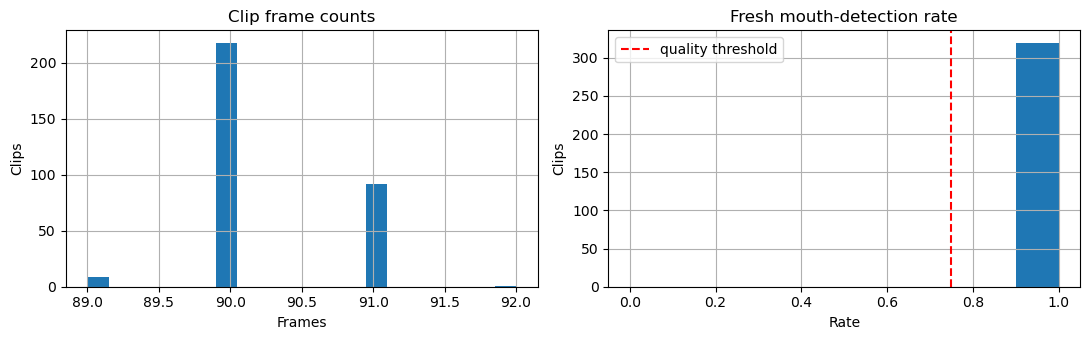

In [6]:
def audit_dataset() -> tuple[pd.DataFrame, pd.DataFrame]:
    manifest = load_manifest()
    issues: list[dict[str, str]] = []
    if manifest.empty:
        return manifest, pd.DataFrame([{'sample_id': '', 'issue': 'Manifest is empty.'}])

    duplicates = manifest.duplicated(['speaker_id', 'label', 'repetition'], keep=False)
    for row in manifest[duplicates].itertuples(index=False):
        issues.append({'sample_id': str(row.sample_id), 'issue': 'Duplicate speaker/label/repetition slot.'})

    referenced_paths: set[Path] = set()
    for row in manifest.itertuples(index=False):
        sample_id = str(row.sample_id)
        if str(row.label) not in WORDS:
            issues.append({'sample_id': sample_id, 'issue': f'Unknown label: {row.label}'})
        path = OUTPUT_ROOT / str(row.relative_path)
        referenced_paths.add(path.resolve())
        if not path.is_file():
            issues.append({'sample_id': sample_id, 'issue': f'Missing archive: {path}'})
            continue
        try:
            with np.load(path, allow_pickle=False) as archive:
                if 'frames' not in archive.files:
                    raise ValueError('missing frames array')
                frames = archive['frames']
                if frames.dtype != np.uint8:
                    raise ValueError(f'frames dtype is {frames.dtype}, expected uint8')
                if frames.ndim != 3 or frames.shape[1:] != (FRAME_HEIGHT, FRAME_WIDTH):
                    raise ValueError(f'frames shape is {frames.shape}')
                if len(frames) != int(row.frame_count):
                    raise ValueError('frame count differs from manifest')
                if str(archive['label'].item()) != str(row.label):
                    raise ValueError('embedded label differs from manifest')
                if str(archive['speaker_id'].item()) != str(row.speaker_id):
                    raise ValueError('embedded speaker differs from manifest')
        except (OSError, ValueError, EOFError) as error:
            issues.append({'sample_id': sample_id, 'issue': str(error)})

    clips_root = OUTPUT_ROOT / 'clips'
    if clips_root.is_dir():
        for path in clips_root.rglob('*.npz'):
            if path.resolve() not in referenced_paths:
                issues.append({'sample_id': '', 'issue': f'Orphaned archive: {path}'})

    return manifest, pd.DataFrame(issues, columns=['sample_id', 'issue'])


manifest, audit_issues = audit_dataset()
if audit_issues.empty:
    display(Markdown('### ✅ Dataset integrity checks passed'))
else:
    display(Markdown(f'### ⚠️ {len(audit_issues)} dataset issue(s) found'))
    display(audit_issues)

if not manifest.empty:
    counts = manifest.pivot_table(index='speaker_id', columns='label', values='sample_id', aggfunc='count', fill_value=0)
    display(Markdown('### Accepted clips by speaker and label'))
    display(counts.reindex(columns=WORDS, fill_value=0))

    expected = pd.MultiIndex.from_product([[SPEAKER_ID], WORDS, range(1, NUM_ROUNDS + 1)], names=['speaker_id', 'label', 'repetition'])
    actual = pd.MultiIndex.from_frame(manifest[['speaker_id', 'label', 'repetition']].assign(repetition=lambda x: x.repetition.astype(int)))
    missing = expected.difference(actual)
    print(f'Missing clips for {SPEAKER_ID}: {len(missing)}')
    if len(missing):
        display(pd.DataFrame(missing.tolist(), columns=missing.names).head(30))

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    manifest['frame_count'].astype(float).hist(ax=axes[0], bins=20)
    axes[0].set(title='Clip frame counts', xlabel='Frames', ylabel='Clips')
    manifest['detection_rate'].astype(float).hist(ax=axes[1], bins=np.linspace(0, 1, 11))
    axes[1].axvline(MIN_DETECTION_RATE, color='red', linestyle='--', label='quality threshold')
    axes[1].set(title='Fresh mouth-detection rate', xlabel='Rate', ylabel='Clips')
    axes[1].legend()
    plt.tight_layout()
    plt.show()

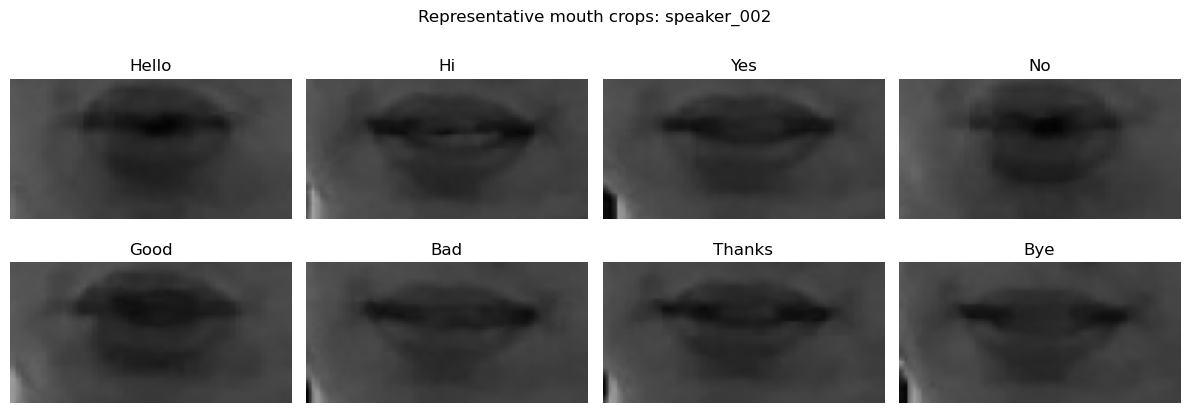

In [7]:
def show_contact_sheet(manifest: pd.DataFrame, speaker_id: str | None = None) -> None:
    rows = manifest.copy()
    if speaker_id is not None:
        rows = rows[rows['speaker_id'].astype(str) == speaker_id]
    if rows.empty:
        print('No clips are available for a contact sheet.')
        return
    rows = rows.sort_values(['label', 'repetition']).groupby('label', as_index=False).first()
    fig, axes = plt.subplots(2, 4, figsize=(12, 4.5))
    for axis, label in zip(axes.flat, WORDS):
        match = rows[rows['label'].astype(str) == label]
        if match.empty:
            axis.text(0.5, 0.5, 'missing', ha='center', va='center')
        else:
            row = match.iloc[0]
            with np.load(OUTPUT_ROOT / row['relative_path'], allow_pickle=False) as archive:
                frames = archive['frames']
                axis.imshow(frames[len(frames) // 2], cmap='gray', vmin=0, vmax=255)
        axis.set_title(label.title())
        axis.axis('off')
    plt.suptitle(f'Representative mouth crops: {speaker_id or "all speakers"}')
    plt.tight_layout()
    plt.show()


manifest = load_manifest()
show_contact_sheet(manifest, SPEAKER_ID)

## 6. Reproducible, on-demand augmentation

Augmentation does **not** create new articulations or new speakers. It only makes training less sensitive to small camera, timing, and lighting changes. Spatial parameters are held constant across a clip to avoid artificial frame-to-frame shaking. Original arrays are never changed.

Apply augmentation only after splitting by speaker, and only to training clips. Never augment validation or test clips.

In [8]:
def temporal_resample(frames: np.ndarray, output_length: int) -> np.ndarray:
    if output_length <= 0:
        raise ValueError('output_length must be positive.')
    if len(frames) == output_length:
        return frames.copy()
    positions = np.linspace(0, len(frames) - 1, output_length)
    left = np.floor(positions).astype(int)
    right = np.minimum(left + 1, len(frames) - 1)
    weights = (positions - left).astype(np.float32)[:, None, None]
    result = frames[left].astype(np.float32) * (1.0 - weights) + frames[right].astype(np.float32) * weights
    return np.clip(np.rint(result), 0, 255).astype(np.uint8)


def augment_clip(frames: np.ndarray, seed: int) -> np.ndarray:
    source = np.asarray(frames)
    if source.dtype != np.uint8 or source.ndim != 3:
        raise ValueError('frames must be uint8 with shape (time, height, width).')
    if len(source) == 0 or source.shape[1:] != (FRAME_HEIGHT, FRAME_WIDTH):
        raise ValueError(f'Expected non-empty clips shaped (time, {FRAME_HEIGHT}, {FRAME_WIDTH}).')
    rng = np.random.default_rng(seed)

    speed = rng.uniform(0.85, 1.15)
    output_length = max(1, int(round(len(source) / speed)))
    augmented = temporal_resample(source, output_length)

    angle = rng.uniform(-4.0, 4.0)
    scale = rng.uniform(0.94, 1.06)
    translate_x = rng.uniform(-3.0, 3.0)
    translate_y = rng.uniform(-2.0, 2.0)
    matrix = cv2.getRotationMatrix2D((FRAME_WIDTH / 2, FRAME_HEIGHT / 2), angle, scale)
    matrix[:, 2] += (translate_x, translate_y)
    augmented = np.stack([
        cv2.warpAffine(frame, matrix, (FRAME_WIDTH, FRAME_HEIGHT), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
        for frame in augmented
    ])

    if rng.random() < 0.5:
        augmented = augmented[:, :, ::-1].copy()
    contrast = rng.uniform(0.85, 1.15)
    brightness = rng.uniform(-12.0, 12.0)
    augmented = augmented.astype(np.float32) * contrast + brightness
    if rng.random() < 0.25:
        augmented = np.stack([cv2.GaussianBlur(frame, (3, 3), 0) for frame in augmented])
    noise_sigma = rng.uniform(0.0, 4.0)
    if noise_sigma > 0:
        augmented += rng.normal(0.0, noise_sigma, size=augmented.shape).astype(np.float32)
    return np.clip(np.rint(augmented), 0, 255).astype(np.uint8)


# Lightweight self-tests: determinism, input immutability, shape/type/range, and temporal variation.
synthetic = np.zeros((60, FRAME_HEIGHT, FRAME_WIDTH), dtype=np.uint8)
for index in range(len(synthetic)):
    cv2.circle(synthetic[index], (20 + index // 3, 25), 7, 180, -1)
original = synthetic.copy()
first = augment_clip(synthetic, seed=123)
second = augment_clip(synthetic, seed=123)
assert np.array_equal(synthetic, original), 'augment_clip mutated its input'
assert np.array_equal(first, second), 'same seed did not reproduce the same augmentation'
assert first.dtype == np.uint8 and first.shape[1:] == (FRAME_HEIGHT, FRAME_WIDTH)
assert 0 <= int(first.min()) <= int(first.max()) <= 255
assert any(len(augment_clip(synthetic, seed=i)) != len(synthetic) for i in range(20)), 'temporal augmentation did not vary length'
print('Augmentation self-tests passed.')

Augmentation self-tests passed.


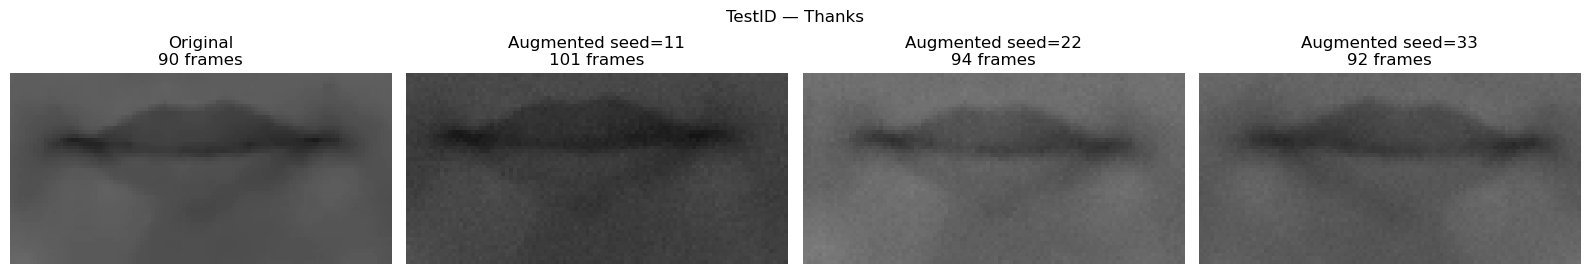

In [9]:
def preview_augmentations(manifest: pd.DataFrame, seeds=(11, 22, 33)) -> None:
    if manifest.empty:
        print('Record at least one clip before previewing augmentation.')
        return
    row = manifest.iloc[0]
    with np.load(OUTPUT_ROOT / row['relative_path'], allow_pickle=False) as archive:
        original = archive['frames'].copy()
    variants = [original] + [augment_clip(original, seed) for seed in seeds]
    titles = ['Original'] + [f'Augmented seed={seed}' for seed in seeds]
    fig, axes = plt.subplots(1, len(variants), figsize=(4 * len(variants), 3))
    for axis, variant, title in zip(np.atleast_1d(axes), variants, titles):
        axis.imshow(variant[len(variant) // 2], cmap='gray', vmin=0, vmax=255)
        axis.set_title(f'{title}\n{len(variant)} frames')
        axis.axis('off')
    plt.suptitle(f'{row["speaker_id"]} — {str(row["label"]).title()}')
    plt.tight_layout()
    plt.show()


manifest = load_manifest()
preview_augmentations(manifest)

## 7. Speaker-level train/validation/test splits

Choose entire speakers for validation and testing only after enough people have contributed. Leave both lists empty while collecting. The helper refuses unknown or overlapping speakers and never chooses holdout speakers automatically.

In [10]:
VALIDATION_SPEAKERS: list[str] = []  # Example later: ['speaker_004']
TEST_SPEAKERS: list[str] = []        # Example later: ['speaker_005']


def assign_speaker_splits(
    manifest: pd.DataFrame,
    validation_speakers: list[str],
    test_speakers: list[str],
) -> pd.DataFrame:
    validation = set(map(str, validation_speakers))
    test = set(map(str, test_speakers))
    overlap = validation.intersection(test)
    if overlap:
        raise ValueError(f'Speakers cannot be in both validation and test: {sorted(overlap)}')
    known = set(manifest['speaker_id'].astype(str)) if not manifest.empty else set()
    unknown = (validation | test).difference(known)
    if unknown:
        raise ValueError(f'Unknown holdout speakers: {sorted(unknown)}')

    result = manifest.copy()
    result['split'] = 'train'
    result.loc[result['speaker_id'].astype(str).isin(validation), 'split'] = 'validation'
    result.loc[result['speaker_id'].astype(str).isin(test), 'split'] = 'test'
    if not result.empty and not (result['split'] == 'train').any():
        raise ValueError('At least one speaker must remain in the training split.')
    return result


manifest = load_manifest()
split_manifest = assign_speaker_splits(manifest, VALIDATION_SPEAKERS, TEST_SPEAKERS)
if not split_manifest.empty:
    display(split_manifest.groupby(['split', 'speaker_id']).size().rename('clips').to_frame())
speaker_count = len(set(manifest['speaker_id'].astype(str))) if not manifest.empty else 0
if speaker_count < 3:
    print('Collect at least three speakers before creating non-empty train/validation/test splits.')
else:
    print('Speaker-level split configuration is ready. Augment only rows whose split is train.')

clips
split speaker_id        
train TestID         160
      speaker_002    160

Collect at least three speakers before creating non-empty train/validation/test splits.


## Next step

Repeat the collection with a new anonymous `SPEAKER_ID` for each participant. Aim for at least five speakers with variation in lighting, camera position, appearance, and natural pronunciation. Once collection is complete, build a separate training notebook that reads `manifest.csv`, holds out entire speakers, and calls `augment_clip` only for training samples.